# 第171章: 模倣学習と行動トークン化 — デモから方針を作る

## Imitation Learning and Action Tokenization

---

### このノートブックの位置づけ

Notebook 170 で方針を勾配で学習しました。A2C は未知配置でスクリプト方針に近い
成功率まで届きましたが、そこに **2,000 エピソードの試行錯誤** を要しました。

実機のロボットでは 2,000 回の失敗は許容できません（部品が壊れる・時間が足りない・危険）。
一方、人間は**正解の動きを見せる**ことができます。

この章では「見せられた動きを真似る」＝**模倣学習**を扱い、さらに
**行動を離散トークンにする**という、言語モデルと行動を繋ぐ鍵になる技を学びます。

### 学習目標

この章を終えると、以下ができるようになります：

- [ ] 模倣学習（Behavior Cloning）を教師あり学習として定式化できる
- [ ] デモ数と性能の関係を測定できる
- [ ] **共変量シフト**が BC を壊す機構を説明し、実験で再現できる
- [ ] 連続行動をビン分割で離散トークンにできる（RT-2 型）
- [ ] VQ で行動の「語彙」を作れる（Notebook 144 の VQ-VAE を行動空間に適用）
- [ ] 離散化の粒度と制御精度のトレードオフを、タスクの許容誤差との関係で説明できる
- [ ] Action Chunking が効く条件・効かない条件を説明できる

### 前提知識

| ノートブック | トピック |
|---|---|
| 170 | 方針勾配と Actor-Critic、ArmWorld、ScriptedExpert |
| 144 | Genie（VQ-VAE による潜在行動の離散化） |
| 161 | トークン化と BPE（語彙という考え方） |
| 164 | GPT（自己回帰生成） |
| 03 | モデル評価指標（教師あり学習の評価） |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

## 目次

1. [環境セットアップ](#setup)
2. [デモンストレーションを集める](#demos)
3. [Behavior Cloning — 教師あり学習としての方針](#bc)
4. [デモ数と性能](#data)
5. [共変量シフト — BC が壊れる場所](#shift)
6. [行動を離散化する — ビン分割（RT-2 型）](#bins)
7. [行動を「語彙」にする — VQ コードブック](#vq)
8. [Action Chunking — 測ったら効かなかった](#chunk)
9. [まとめとチートシート](#summary)
10. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import sys
import pathlib
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

_here = pathlib.Path.cwd()
for _cand in (_here, _here / "notebooks" / "vla", _here.parent):
    if (_cand / "utils" / "armworld.py").exists():
        sys.path.insert(0, str(_cand))
        break
from utils import ArmWorld, ScriptedExpert, forward_kinematics, rollout  # noqa: E402

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

MAX_STEPS = 60          # 本章は許容誤差を厳しくする実験があるので 170 より長めに取る
EVAL_SEEDS = range(5000, 5100)     # 学習に使わない100配置で評価する

print("torch:", torch.__version__)
print("evaluation configurations:", len(list(EVAL_SEEDS)))

torch: 2.9.1
evaluation configurations: 100


---

<a id="demos"></a>
## 2. デモンストレーションを集める

Notebook 170 で作った `ScriptedExpert` を「人間の代わり」として使います。
これは減衰付き最小二乗でヤコビアンを解く手書きの制御器で、学習器ではありません。

実機では人間がジョイスティックや VR コントローラで動かした軌跡を使います。
**どちらにしても模倣学習側から見れば「状態と行動の対の集まり」**です。

In [2]:
# ============================================================
# デモ軌跡の収集
# ============================================================

def collect_demos(n_demos: int, chunk: int = 1, noise: float = 0.0,
                  seed0: int = 0, success_radius: float = 0.15):
    '''ScriptedExpert で n_demos 本の軌跡を集め、(状態, 行動) の対にする。

    chunk > 1 のとき、各時刻の教師信号を「これから K ステップ分の行動」にする
    （Action Chunking 用。末尾は最後の行動で埋める）。
    '''
    states, actions, lengths, successes = [], [], [], []
    for sd in range(seed0, seed0 + n_demos):
        env = ArmWorld(task="reach", seed=sd, image_obs=False,
                       max_steps=MAX_STEPS, success_radius=success_radius)
        traj = rollout(env, ScriptedExpert(noise=noise, seed=sd))
        s, a = traj["states"], traj["actions"][:, :2]
        if chunk > 1:
            padded = np.concatenate([a, np.tile(a[-1:], (chunk, 1))])
            a = np.stack([padded[i:i + chunk].reshape(-1) for i in range(len(s))])
        states.append(s); actions.append(a)
        lengths.append(len(s)); successes.append(traj["success"])
    return (np.concatenate(states), np.concatenate(actions),
            np.array(lengths), float(np.mean(successes)))


t0 = time.time()
demo_S, demo_A, demo_len, demo_success = collect_demos(100)
print(f"collected 100 demos in {time.time() - t0:.2f}s")
print(f"  transitions     : {len(demo_S)}")
print(f"  state dim       : {demo_S.shape[1]} (proprio 7 + target-relative 2)")
print(f"  action dim      : {demo_A.shape[1]}")
print(f"  episode length  : mean {demo_len.mean():.1f}, max {demo_len.max()}")
print(f"  expert success  : {demo_success:.2f}")

collected 100 demos in 0.07s
  transitions     : 1391
  state dim       : 9 (proprio 7 + target-relative 2)
  action dim      : 2
  episode length  : mean 13.9, max 60
  expert success  : 0.99


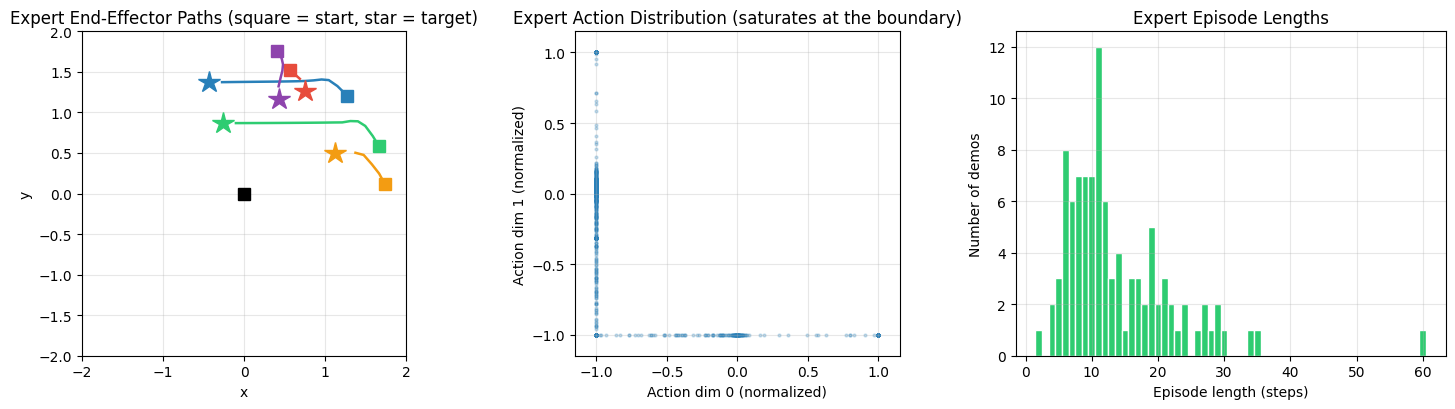

fraction of expert actions at the +-1 boundary: 67.5%
-> 専門家は『全速で向かう』挙動をとる。行動分布が境界に張り付いていることは
   のちの離散化（ビン分割）でビンの使われ方に効いてくる。


In [3]:
# ============================================================
# 図1: デモの中身を見る
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# --- 左: エンドエフェクタの軌跡 ---
ax = axes[0]
for sd, color in zip([0, 1, 2, 3, 4], ["#2980B9", "#E74C3C", "#2ECC71", "#F39C12", "#8E44AD"]):
    env = ArmWorld(task="reach", seed=sd, image_obs=False, max_steps=MAX_STEPS)
    env.reset(seed=sd)
    path = []
    expert = ScriptedExpert()
    for _ in range(MAX_STEPS):
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
        _, _, done, _ = env.step(expert.act(env))
        if done:
            break
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "-", color=color, lw=1.8)
    ax.plot(path[0, 0], path[0, 1], "s", color=color, ms=8)
    ax.plot(env.target[0], env.target[1], "*", color=color, ms=16)
ax.plot(0, 0, "ks", ms=9)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Expert End-Effector Paths (square = start, star = target)")

# --- 中: 行動の分布 ---
ax = axes[1]
ax.scatter(demo_A[:, 0], demo_A[:, 1], s=4, alpha=0.25, color="#2980B9")
ax.set_xlabel("Action dim 0 (normalized)")
ax.set_ylabel("Action dim 1 (normalized)")
ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect("equal")
ax.set_title("Expert Action Distribution (saturates at the boundary)")

# --- 右: エピソード長 ---
ax = axes[2]
ax.hist(demo_len, bins=np.arange(demo_len.min() - 0.5, demo_len.max() + 1.5),
        color="#2ECC71", edgecolor="white")
ax.set_xlabel("Episode length (steps)")
ax.set_ylabel("Number of demos")
ax.set_title("Expert Episode Lengths")

plt.tight_layout()
plt.show()

saturated = np.mean(np.abs(demo_A) > 0.99)
print(f"fraction of expert actions at the +-1 boundary: {saturated:.1%}")
print("-> 専門家は『全速で向かう』挙動をとる。行動分布が境界に張り付いていることは")
print("   のちの離散化（ビン分割）でビンの使われ方に効いてくる。")

---

<a id="bc"></a>
## 3. Behavior Cloning — 教師あり学習としての方針

模倣学習の最も単純な形が **Behavior Cloning (BC)** です。
状態を入力、専門家の行動を出力とする**ただの回帰問題**として解きます。

$$\min_\theta \ \mathbb{E}_{(s,a)\sim \mathcal{D}}\left[\lVert \pi_\theta(s) - a \rVert^2\right]$$

強化学習の要素は何も入っていません。報酬も価値関数も Advantage も要りません。
Notebook 170 の方針勾配と比べると驚くほど簡単です。

| | 方針勾配 (170) | Behavior Cloning (本章) |
|---|---|---|
| 必要なもの | 環境との試行 + 報酬 | **デモ軌跡だけ** |
| 損失 | $-\log\pi(a\vert s)\cdot A_t$ | $\lVert \pi_\theta(s) - a\rVert^2$ |
| 試行回数 | 2,000 エピソード | **0** |
| 探索 | 必要 | 不要 |
| 弱点 | 分散・サンプル効率 | **デモの分布から外れると崩れる** |

In [4]:
# ============================================================
# BC の実装と評価
# ============================================================

def mlp(n_in: int, n_out: int, hidden: int = 64) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.Tanh(),
        nn.Linear(hidden, hidden), nn.Tanh(),
        nn.Linear(hidden, n_out),
    )


def train_bc(states, actions, epochs: int = 150, lr: float = 1e-3,
             batch_size: int = 128, seed: int = SEED):
    '''状態 -> 行動 の回帰。これだけが模倣学習の学習部分。'''
    torch.manual_seed(seed)
    net = mlp(states.shape[1], actions.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.as_tensor(states)
    Y = torch.as_tensor(actions)
    history = []
    for _ in range(epochs):
        order = torch.randperm(len(X))
        epoch_loss = 0.0
        for i in range(0, len(X), batch_size):
            idx = order[i:i + batch_size]
            loss = ((net(X[idx]) - Y[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            epoch_loss += float(loss.detach()) * len(idx)
        history.append(epoch_loss / len(X))
    return net, np.array(history)


def make_eval_env(seed: int, out_of_distribution: bool = False,
                  success_radius: float = 0.15):
    '''評価用の環境。out_of_distribution=True でデモに無い初期姿勢から始める。'''
    env = ArmWorld(task="reach", seed=seed, image_obs=False,
                   max_steps=MAX_STEPS, success_radius=success_radius)
    env.reset(seed=seed)
    if out_of_distribution:
        # デモの初期姿勢は theta ~ U(0.2,1.4) x U(-1.0,1.0)。その外から始める。
        rng = np.random.default_rng(seed + 99991)
        env.theta = np.array([rng.uniform(1.8, 2.8), rng.uniform(1.4, 2.4)])
    return env


def evaluate_policy(net, chunk: int = 1, execute_whole_chunk: bool = False,
                    out_of_distribution: bool = False, obs_noise: float = 0.0,
                    success_radius: float = 0.15, seeds=EVAL_SEEDS):
    '''成功率を返す。chunk/ノイズ/分布外の条件を切り替えられる。'''
    rng = np.random.default_rng(0)
    n_success = 0
    for sd in seeds:
        env = make_eval_env(sd, out_of_distribution, success_radius)
        done, info, t = False, {"success": False}, 0
        while t < MAX_STEPS and not done:
            state = env.state_vec()
            if obs_noise > 0:
                state = state + rng.normal(0, obs_noise, state.shape).astype(np.float32)
            with torch.no_grad():
                out = net(torch.as_tensor(state)).numpy()
            actions = out.reshape(-1, 2)
            to_execute = actions if execute_whole_chunk else actions[:1]
            for a in to_execute:
                _, _, done, info = env.step(np.concatenate([a, [0.0]]))
                t += 1
                if done:
                    break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


t0 = time.time()
bc_net, bc_history = train_bc(demo_S, demo_A)
bc_success = evaluate_policy(bc_net)
print(f"BC trained in {time.time() - t0:.1f}s")
print(f"  final training MSE : {bc_history[-1]:.5f}")
print(f"  success rate       : {bc_success:.2f}   (100 unseen configurations)")
print(f"  expert reference   : {demo_success:.2f}")
print()
print("試行0回・報酬なしで、2,000エピソード回した 170 の A2C と同等以上になる。")

BC trained in 1.1s
  final training MSE : 0.00202
  success rate       : 0.99   (100 unseen configurations)
  expert reference   : 0.99

試行0回・報酬なしで、2,000エピソード回した 170 の A2C と同等以上になる。


---

<a id="data"></a>
## 4. デモ数と性能

BC は教師あり学習なので、**データ量が性能を決めます**。何本のデモが必要かを測ります。

swept 5 dataset sizes in 3.8s


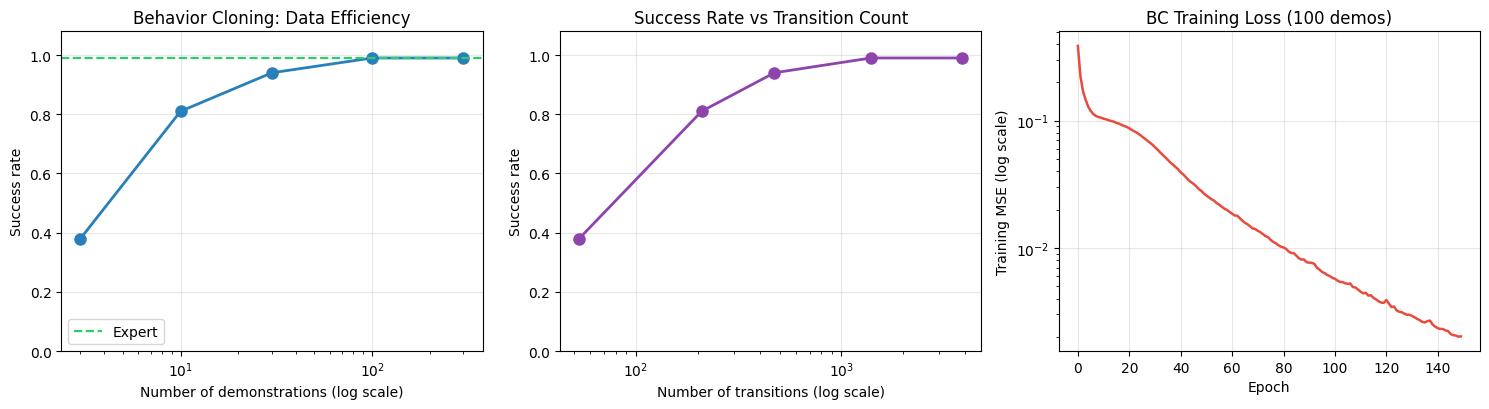

 demos  transitions   train MSE   success
     3           53     0.01698      0.38
    10          209     0.01226      0.81
    30          472     0.02528      0.94
   100         1391     0.00202      0.99
   300         3867     0.00032      0.99


In [5]:
# ============================================================
# 図2: デモ数 vs 成功率
# ============================================================

demo_counts = [3, 10, 30, 100, 300]
data_curve = []
t0 = time.time()
for n in demo_counts:
    S, A, lengths, _ = collect_demos(n)
    net, hist = train_bc(S, A, epochs=300 if n < 30 else 150)
    data_curve.append({"n": n, "transitions": len(S),
                       "success": evaluate_policy(net), "mse": hist[-1]})
print(f"swept {len(demo_counts)} dataset sizes in {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.plot([d["n"] for d in data_curve], [d["success"] for d in data_curve],
        "o-", color="#2980B9", lw=2, ms=8)
ax.axhline(demo_success, color="#2ECC71", ls="--", lw=1.6, label="Expert")
ax.set_xscale("log")
ax.set_xlabel("Number of demonstrations (log scale)")
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.08)
ax.set_title("Behavior Cloning: Data Efficiency")
ax.legend()

ax = axes[1]
ax.plot([d["transitions"] for d in data_curve], [d["success"] for d in data_curve],
        "o-", color="#8E44AD", lw=2, ms=8)
ax.set_xscale("log")
ax.set_xlabel("Number of transitions (log scale)")
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.08)
ax.set_title("Success Rate vs Transition Count")

ax = axes[2]
ax.plot(bc_history, color="#E74C3C", lw=1.8)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training MSE (log scale)")
ax.set_title("BC Training Loss (100 demos)")

plt.tight_layout()
plt.show()

print(f"{'demos':>6s} {'transitions':>12s} {'train MSE':>11s} {'success':>9s}")
for d in data_curve:
    print(f"{d['n']:6d} {d['transitions']:12d} {d['mse']:11.5f} {d['success']:9.2f}")

### 読み取れること

- **30本程度のデモで実用域に入る**。この環境は決定論的で専門家も一貫しているため、
  必要なデモ数は少なくて済みます。
- 3本だと崩れます。訪れる状態の種類が足りず、**見たことのない状態で何をすべきか
  分からない**からです。これが次節の共変量シフトの入口です。
- 訓練 MSE はデモ数が増えても下がり切らず、むしろ少量データの方が小さくなります。
  **訓練誤差は性能の指標にならない**（Notebook 03 の過学習の話と同じ）。

---

<a id="shift"></a>
## 5. 共変量シフト — BC が壊れる場所

BC の弱点は、教師あり学習の前提である **i.i.d.（訓練とテストが同じ分布）が成り立たない**
ことです。

- 訓練データの状態分布は **専門家の方針** $\pi^*$ が訪れた状態の分布 $d^{\pi^*}$
- テスト時の状態分布は **学習した方針** $\pi_\theta$ が訪れた状態の分布 $d^{\pi_\theta}$

$\pi_\theta$ がわずかに誤ると、専門家が決して訪れない状態に入ります。
そこでの振る舞いは学習されていないので、さらに誤ります。**誤差が累積します**。

$T$ ステップで誤差が $O(\epsilon T^2)$ に増えることが知られています（$\epsilon$ は1ステップの誤り率）。
線形ではなく**二乗**で増えるのが共変量シフトの厄介さです。

### 実験で再現する

デモの初期姿勢は $\theta \sim U(0.2, 1.4) \times U(-1.0, 1.0)$ です。
評価時に**その外**から始めれば、人工的に「分布外の状態」を作れます。

evaluated in 2.7s


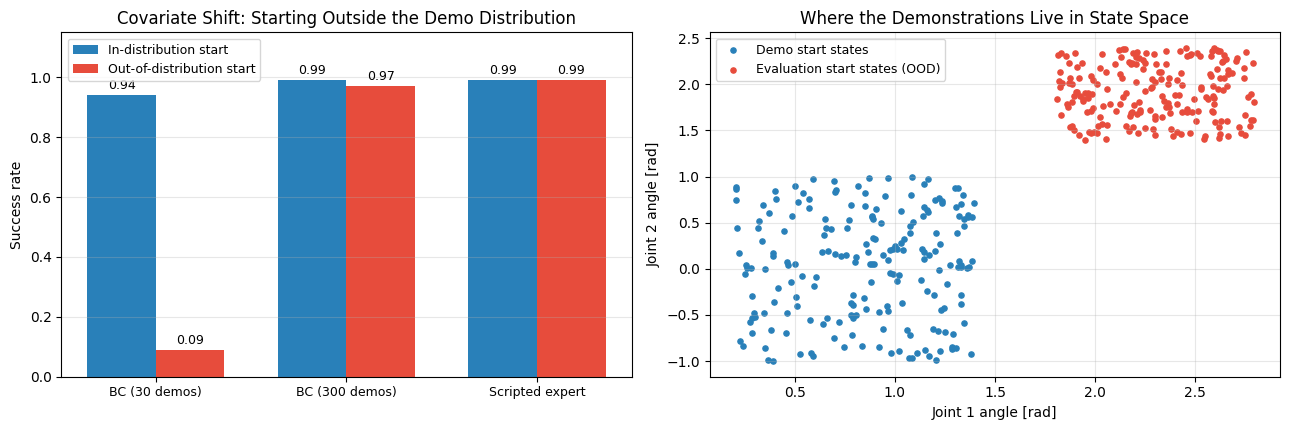

BC(30)  in-distribution 0.94 -> out-of-distribution 0.09   (-0.85)
BC(300) in-distribution 0.99 -> out-of-distribution 0.97   (-0.02)
expert  out-of-distribution 0.99  <- 環境自体は分布外でも解ける


In [6]:
# ============================================================
# 図3: 共変量シフトの実測
# ============================================================

t0 = time.time()
S30, A30, _, _ = collect_demos(30)
net30, _ = train_bc(S30, A30)
S300, A300, _, _ = collect_demos(300)
net300, _ = train_bc(S300, A300)

# 専門家を分布外で評価（環境が解けることの確認）
expert = ScriptedExpert()
expert_ood = 0
for sd in EVAL_SEEDS:
    env = make_eval_env(sd, out_of_distribution=True)
    done, info = False, {"success": False}
    for _ in range(MAX_STEPS):
        _, _, done, info = env.step(expert.act(env))
        if done:
            break
    expert_ood += bool(info["success"])
expert_ood /= len(list(EVAL_SEEDS))

rows = [
    ("BC (30 demos)",  evaluate_policy(net30),  evaluate_policy(net30, out_of_distribution=True)),
    ("BC (300 demos)", evaluate_policy(net300), evaluate_policy(net300, out_of_distribution=True)),
    ("Scripted expert", demo_success, expert_ood),
]
print(f"evaluated in {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
x = np.arange(len(rows))
w = 0.36
ax.bar(x - w / 2, [r[1] for r in rows], w, color="#2980B9", label="In-distribution start")
ax.bar(x + w / 2, [r[2] for r in rows], w, color="#E74C3C", label="Out-of-distribution start")
for i, r in enumerate(rows):
    ax.text(i - w / 2, r[1] + 0.02, f"{r[1]:.2f}", ha="center", fontsize=9)
    ax.text(i + w / 2, r[2] + 0.02, f"{r[2]:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows], fontsize=9)
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.15)
ax.set_title("Covariate Shift: Starting Outside the Demo Distribution")
ax.legend(fontsize=9)
ax.grid(axis="x")

# 右: デモが覆う状態領域を可視化
ax = axes[1]
in_dist, ood = [], []
for sd in range(200):
    env = make_eval_env(sd, out_of_distribution=False)
    in_dist.append(env.theta.copy())
    env = make_eval_env(sd, out_of_distribution=True)
    ood.append(env.theta.copy())
in_dist, ood = np.array(in_dist), np.array(ood)
ax.scatter(in_dist[:, 0], in_dist[:, 1], s=14, color="#2980B9", label="Demo start states")
ax.scatter(ood[:, 0], ood[:, 1], s=14, color="#E74C3C", label="Evaluation start states (OOD)")
ax.set_xlabel("Joint 1 angle [rad]")
ax.set_ylabel("Joint 2 angle [rad]")
ax.set_title("Where the Demonstrations Live in State Space")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"BC(30)  in-distribution {rows[0][1]:.2f} -> out-of-distribution {rows[0][2]:.2f}"
      f"   ({rows[0][2] - rows[0][1]:+.2f})")
print(f"BC(300) in-distribution {rows[1][1]:.2f} -> out-of-distribution {rows[1][2]:.2f}"
      f"   ({rows[1][2] - rows[1][1]:+.2f})")
print(f"expert  out-of-distribution {expert_ood:.2f}  <- 環境自体は分布外でも解ける")

### 何が起きたか

- **BC(30) は分布外で大きく落ちました**。環境は解けるのに（専門家は分布外でも成功）、
  方針が「そこで何をすべきか」を知りません。これが共変量シフトです。
- **BC(300) は落ちません**。デモが多いと訪れる状態の種類も増え、
  評価時の状態が偶然カバーされます。「データで殴る」は有効な対策です。
- ただし実機では、**カバーしたい状態を人間が意図的に見せる**必要があります。
  これが DAgger の発想です。

### DAgger の直感

**DAgger (Dataset Aggregation)** は、データ収集を学習中の方針に追従させます。

1. 現在の方針 $\pi_\theta$ で環境を動かす（＝$d^{\pi_\theta}$ から状態をサンプルする）
2. その状態で**専門家に正解を聞く**（$a^* = \pi^*(s)$）
3. $(s, a^*)$ をデータセットに追加して再学習
4. 1に戻る

訓練分布をテスト分布に寄せていくので、共変量シフトが原理的に解消します。
代償は「学習中ずっと専門家に問い合わせられる必要がある」ことです。
人間のオペレータが常時待機するのは現実には高コストなので、
実務では「失敗した場面だけ人が介入する」などの折衷が使われます。

> **本章では DAgger は実装しません**。`ScriptedExpert` は常時問い合わせ可能なので
> 実装は容易ですが、「専門家に無限に聞ける」という前提が実機で成立せず、
> 教材としての示唆が薄いためです。重要なのは**分布を寄せるという考え方**です。

---

<a id="bins"></a>
## 6. 行動を離散化する — ビン分割（RT-2 型）

ここから話が VLA に繋がります。

言語モデルは**離散トークンの列**を扱います（Notebook 161 の BPE、164 の GPT）。
もし行動も離散トークンにできれば、**行動を言語モデルに吐かせられます**。
これが RT-2 の発想です：行動の各次元を一様に区切り、
区間のインデックスを「語彙」に割り当てる。

$$a_i \in [-1, 1] \ \longrightarrow\ \text{token} = \arg\min_j \lvert a_i - c_j \rvert,
\quad c_j = -1 + \frac{2j}{B-1}$$

連続値の回帰問題が、**$B$ クラスの分類問題**に変わります。

In [7]:
# ============================================================
# ビン分割によるトークン化と、分類としての BC
# ============================================================

def tokenize(actions: np.ndarray, n_bins: int):
    '''各次元を [-1,1] の一様な n_bins 個のビンに割り当てる。'''
    centers = np.linspace(-1, 1, n_bins)
    tokens = np.abs(actions[:, :, None] - centers[None, None, :]).argmin(axis=-1)
    return tokens, centers


class TokenPolicy(nn.Module):
    '''状態から各行動次元のトークン分布を出す方針（RT-2 を単純化した形）。'''

    def __init__(self, obs_dim: int, act_dim: int, n_bins: int, hidden: int = 64):
        super().__init__()
        self.act_dim, self.n_bins = act_dim, n_bins
        self.net = mlp(obs_dim, act_dim * n_bins, hidden)

    def forward(self, obs):
        return self.net(obs).view(*obs.shape[:-1], self.act_dim, self.n_bins)


def train_token_policy(states, actions, n_bins: int, epochs: int = 150,
                       lr: float = 1e-3, batch_size: int = 128, seed: int = SEED):
    tokens, centers = tokenize(actions, n_bins)
    torch.manual_seed(seed)
    policy = TokenPolicy(states.shape[1], actions.shape[1], n_bins)
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    X = torch.as_tensor(states)
    T = torch.as_tensor(tokens)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch_size):
            idx = order[i:i + batch_size]
            logits = policy(X[idx])
            loss = F.cross_entropy(logits.reshape(-1, n_bins), T[idx].reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
    quant_error = float(np.abs(centers[tokens] - actions).mean())
    return policy, centers, quant_error


def evaluate_token_policy(policy, centers, success_radius: float = 0.15,
                          seeds=EVAL_SEEDS):
    n_success = 0
    for sd in seeds:
        env = make_eval_env(sd, success_radius=success_radius)
        done, info = False, {"success": False}
        for _ in range(MAX_STEPS):
            with torch.no_grad():
                logits = policy(torch.as_tensor(env.state_vec()))
            a = centers[logits.argmax(-1).numpy()]
            _, _, done, info = env.step(np.concatenate([a, [0.0]]))
            if done:
                break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


print("tokenization helpers ready")
tok_demo, centers_demo = tokenize(demo_A[:5], 11)
print("example: action", np.round(demo_A[0], 3), "-> token", tok_demo[0],
      "-> decoded", np.round(centers_demo[tok_demo[0]], 3))

tokenization helpers ready
example: action [-1. -1.] -> token [0 0] -> decoded [-1. -1.]


bin sweep finished in 9.4s


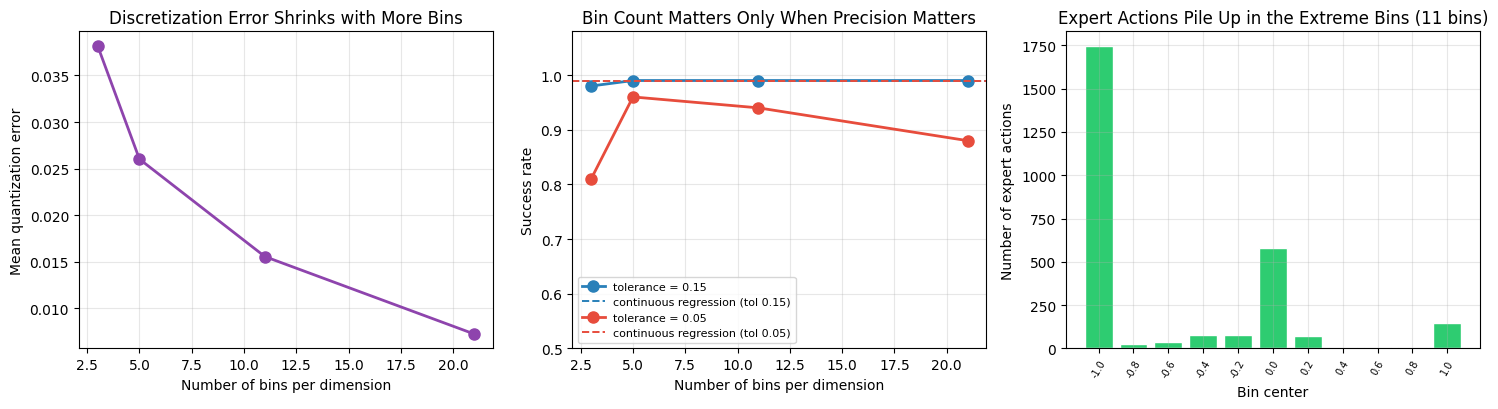

tolerance 0.15: bins= 3 0.98  bins= 5 0.99  bins=11 0.99  bins=21 0.99   continuous 0.99
tolerance 0.05: bins= 3 0.81  bins= 5 0.96  bins=11 0.94  bins=21 0.88   continuous 0.99


In [8]:
# ============================================================
# 図4: ビン数と精度 — タスクの許容誤差で意味が変わる
# ============================================================

bin_sizes = [3, 5, 11, 21]
tolerances = [0.15, 0.05]        # success_radius: 緩い / 厳しい
results_bins = {}

t0 = time.time()
for tol in tolerances:
    S, A, _, _ = collect_demos(100, success_radius=tol)
    row = []
    for B in bin_sizes:
        pol, centers, qerr = train_token_policy(S, A, B)
        row.append({"bins": B, "qerr": qerr,
                    "success": evaluate_token_policy(pol, centers, success_radius=tol)})
    # 連続回帰（離散化しない）の参照値
    cont_net, _ = train_bc(S, A)
    cont = evaluate_policy(cont_net, success_radius=tol)
    results_bins[tol] = {"rows": row, "continuous": cont}
print(f"bin sweep finished in {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.plot(bin_sizes, [r["qerr"] for r in results_bins[0.15]["rows"]],
        "o-", color="#8E44AD", lw=2, ms=8)
ax.set_xlabel("Number of bins per dimension")
ax.set_ylabel("Mean quantization error")
ax.set_title("Discretization Error Shrinks with More Bins")

ax = axes[1]
for tol, color in zip(tolerances, ["#2980B9", "#E74C3C"]):
    ax.plot(bin_sizes, [r["success"] for r in results_bins[tol]["rows"]],
            "o-", color=color, lw=2, ms=8, label=f"tolerance = {tol}")
    ax.axhline(results_bins[tol]["continuous"], color=color, ls="--", lw=1.4,
               label=f"continuous regression (tol {tol})")
ax.set_xlabel("Number of bins per dimension")
ax.set_ylabel("Success rate")
ax.set_ylim(0.5, 1.08)
ax.set_title("Bin Count Matters Only When Precision Matters")
ax.legend(fontsize=8)

ax = axes[2]
tokens_11, centers_11 = tokenize(demo_A, 11)
counts = np.bincount(tokens_11.reshape(-1), minlength=11)
ax.bar(np.round(centers_11, 2).astype(str), counts, color="#2ECC71", edgecolor="white")
ax.set_xlabel("Bin center")
ax.set_ylabel("Number of expert actions")
ax.set_title("Expert Actions Pile Up in the Extreme Bins (11 bins)")
ax.tick_params(axis="x", labelrotation=60, labelsize=7)

plt.tight_layout()
plt.show()

for tol in tolerances:
    line = "  ".join(f"bins={r['bins']:2d} {r['success']:.2f}" for r in results_bins[tol]["rows"])
    print(f"tolerance {tol}: {line}   continuous {results_bins[tol]['continuous']:.2f}")

### 読み取れること — 離散化の代償は「タスクが要求する精度」で決まる

- **量子化誤差はビン数とともに単調に減る**（左図）。これは行動空間だけを見た話。
- しかし**成功率はタスクの許容誤差次第**（中図）。
  許容誤差 0.15 ではビン3個でも十分で、21個にしても変わりません。
  許容誤差 0.05 にすると、ビン3個は明確に落ちます。
- どちらの許容誤差でも、**連続回帰が最も良い**（破線）。
  離散化は「言語モデルに繋げる」という利得のために精度を手放す取引です。
- **ビンを増やせば良くなるわけでもない**。厳しい許容誤差では
  ビン21個がビン5個より悪くなりました。量子化誤差は下がるのに成功率が下がるのは、
  **分類問題が難しくなる**ためです（クラス数が増えてもデータ量は同じ。
  Notebook 25 の高カーディナリティ・カテゴリ変数と同じ構図）。
  量子化誤差とデータ量の両方を見て決める必要があります。
- 右図: 専門家の行動は両端のビンに集中します。これは専門家が「全速で向かう」挙動を
  とるため。**一様なビン分割は語彙を無駄にしています**——使われないビンがある。
  ここが次節の VQ の動機です。

> **実物の RT-2 との違い**: RT-2 は各次元のトークンを**自己回帰的に**（言語モデルとして）
> 生成し、既存の語彙の一部を行動トークンに割り当てます。本章は次元ごとに独立な softmax に
> 単純化しています。自己回帰にする利点は多峰性を表現できることで、それは Notebook 172 の
> 拡散方針と同じ動機です。

---

<a id="vq"></a>
## 7. 行動を「語彙」にする — VQ コードブック

一様なビン分割の問題は、**行動の分布を無視している**ことでした。
使われない区間にも語彙を割り当ててしまいます。

Notebook 144（Genie）では **VQ-VAE** で動画から潜在行動を離散化しました。
同じ考えを行動空間に直接適用します：データに合わせてコードブックを学習する。

さらに、ここでは**1ステップの行動ではなく $K$ ステップの行動の塊（チャンク）**を
1つのコードにします。こうすると「よく使われる動きの型」が語彙になります。

実装は k-means（VQ の最も素朴な形）で行います。
VQ-VAE のコミットメント損失による学習も同じことを微分可能にしたものです。

In [9]:
# ============================================================
# 行動チャンクの VQ コードブック（k-means）
# ============================================================

def learn_codebook(chunks: np.ndarray, codebook_size: int,
                   iterations: int = 60, seed: int = SEED):
    '''行動チャンクの集合から k-means でコードブックを学習する。'''
    rng = np.random.default_rng(seed)
    codebook = chunks[rng.choice(len(chunks), codebook_size, replace=False)].copy()
    for _ in range(iterations):
        dist = ((chunks[:, None, :] - codebook[None]) ** 2).sum(-1)
        labels = dist.argmin(1)
        for j in range(codebook_size):
            members = labels == j
            if members.any():
                codebook[j] = chunks[members].mean(0)
    dist = ((chunks[:, None, :] - codebook[None]) ** 2).sum(-1)
    labels = dist.argmin(1)
    recon = float(np.sqrt(((chunks - codebook[labels]) ** 2).sum(-1)).mean())
    return codebook, labels, recon


def train_code_policy(states, labels, codebook_size: int, epochs: int = 150,
                      lr: float = 1e-3, batch_size: int = 128, seed: int = SEED):
    '''状態からコード番号を分類する方針。出力は「どの動きの型を使うか」。'''
    torch.manual_seed(seed)
    net = mlp(states.shape[1], codebook_size)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X = torch.as_tensor(states)
    T = torch.as_tensor(labels)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch_size):
            idx = order[i:i + batch_size]
            loss = F.cross_entropy(net(X[idx]), T[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    return net


def evaluate_code_policy(net, codebook, seeds=EVAL_SEEDS):
    '''コードを選び、そのチャンクの先頭だけ実行して毎ステップ選び直す。'''
    n_success = 0
    for sd in seeds:
        env = make_eval_env(sd)
        done, info = False, {"success": False}
        for _ in range(MAX_STEPS):
            with torch.no_grad():
                code = int(net(torch.as_tensor(env.state_vec())).argmax())
            a = codebook[code].reshape(-1, 2)[0]
            _, _, done, info = env.step(np.concatenate([a, [0.0]]))
            if done:
                break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


CHUNK_K = 4
chunk_S, chunk_A, _, _ = collect_demos(150, chunk=CHUNK_K)
print(f"action chunks: {chunk_A.shape}  (K={CHUNK_K} steps x 2 dims = {chunk_A.shape[1]})")

t0 = time.time()
codebook_sizes = [8, 16, 32, 64]
vq_rows = []
for k in codebook_sizes:
    cb, labels, recon = learn_codebook(chunk_A, k)
    pol = train_code_policy(chunk_S, labels, k)
    vq_rows.append({"k": k, "recon": recon, "success": evaluate_code_policy(pol, cb),
                    "used": len(np.unique(labels))})
print(f"VQ sweep finished in {time.time() - t0:.1f}s")
for r in vq_rows:
    print(f"  codebook={r['k']:3d}  used={r['used']:3d}  recon error={r['recon']:.4f}"
          f"  success={r['success']:.2f}")

action chunks: (2003, 8)  (K=4 steps x 2 dims = 8)


VQ sweep finished in 5.3s
  codebook=  8  used=  8  recon error=0.2548  success=0.92
  codebook= 16  used= 16  recon error=0.1648  success=0.96
  codebook= 32  used= 32  recon error=0.1397  success=0.97
  codebook= 64  used= 64  recon error=0.0863  success=0.97


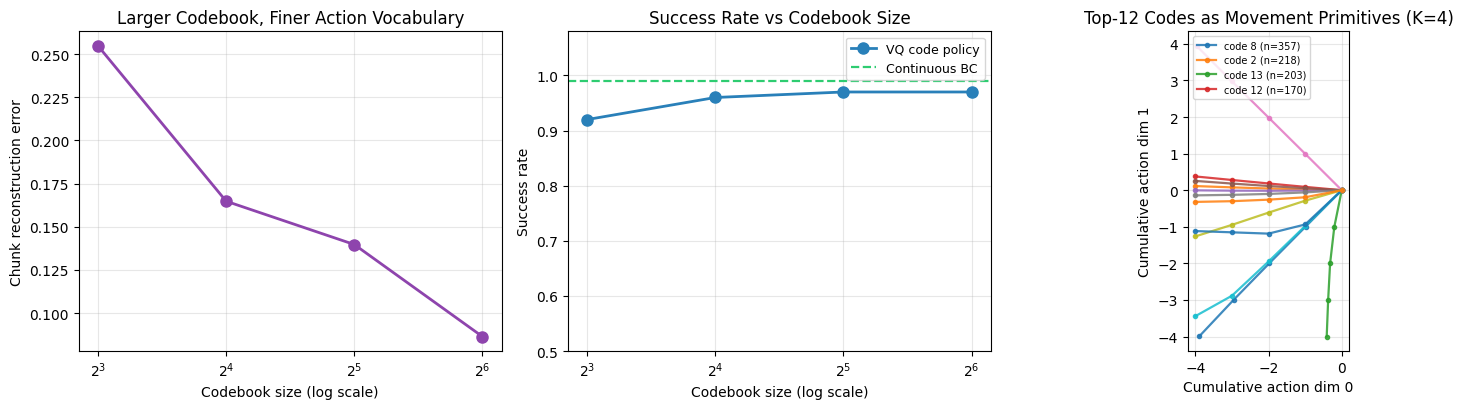

コードブックの各要素は『4ステップ分の動きの型』になっている。
Genie（144）が動画から潜在行動を見つけたのと同じ構造を、行動空間で直接作った形。

一様ビン分割（11分割・2次元）の語彙数: 121 通りの組み合わせ
VQ コードブック(32)の語彙数          : 32 通り（ただし4ステップ分を含む）
-> VQ はデータに出てくる組み合わせだけを語彙にするので、無駄が少ない。


In [10]:
# ============================================================
# 図5: VQ コードブックの可視化
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.plot([r["k"] for r in vq_rows], [r["recon"] for r in vq_rows],
        "o-", color="#8E44AD", lw=2, ms=8)
ax.set_xscale("log", base=2)
ax.set_xlabel("Codebook size (log scale)")
ax.set_ylabel("Chunk reconstruction error")
ax.set_title("Larger Codebook, Finer Action Vocabulary")

ax = axes[1]
ax.plot([r["k"] for r in vq_rows], [r["success"] for r in vq_rows],
        "o-", color="#2980B9", lw=2, ms=8, label="VQ code policy")
ax.axhline(bc_success, color="#2ECC71", ls="--", lw=1.6, label="Continuous BC")
ax.set_xscale("log", base=2)
ax.set_xlabel("Codebook size (log scale)")
ax.set_ylabel("Success rate")
ax.set_ylim(0.5, 1.08)
ax.set_title("Success Rate vs Codebook Size")
ax.legend(fontsize=9)

# 右: コードブックの中身（各コードが EEF の動きの「型」になっている）
ax = axes[2]
cb32, labels32, _ = learn_codebook(chunk_A, 32)
usage = np.bincount(labels32, minlength=32)
order = np.argsort(-usage)
for rank, j in enumerate(order[:12]):
    path = np.concatenate([[[0.0, 0.0]], np.cumsum(cb32[j].reshape(-1, 2), axis=0)])
    ax.plot(path[:, 0], path[:, 1], "-o", ms=3, lw=1.6, alpha=0.85,
            label=f"code {j} (n={usage[j]})" if rank < 4 else None)
ax.set_xlabel("Cumulative action dim 0")
ax.set_ylabel("Cumulative action dim 1")
ax.set_aspect("equal")
ax.set_title("Top-12 Codes as Movement Primitives (K=4)")
ax.legend(fontsize=7, loc="upper left")

plt.tight_layout()
plt.show()

print("コードブックの各要素は『4ステップ分の動きの型』になっている。")
print("Genie（144）が動画から潜在行動を見つけたのと同じ構造を、行動空間で直接作った形。")
print()
print(f"一様ビン分割（11分割・2次元）の語彙数: {11 ** 2} 通りの組み合わせ")
print(f"VQ コードブック(32)の語彙数          : 32 通り（ただし4ステップ分を含む）")
print("-> VQ はデータに出てくる組み合わせだけを語彙にするので、無駄が少ない。")

---

<a id="chunk"></a>
## 8. Action Chunking — 測ったら効かなかった

**Action Chunking**（ACT で有名になった手法）は、1ステップ先ではなく
$K$ ステップ分の行動をまとめて予測し、**まとめて実行**します。

主張されている利点：

1. 高頻度制御で1ステップ予測を繰り返すと、誤差が累積して震える
2. 人間のデモは非マルコフ的（直前の意図を引きずる）なので、1ステップ予測では再現できない
3. まとめて出すと時間的に一貫した動きになる

**本当にそうなのか測ります**。$K$ と観測ノイズを振って、
「先頭だけ実行して毎ステップ再計画」と「$K$ 本すべて実行（開ループ）」を比べます。

chunking experiment finished in 3.4s


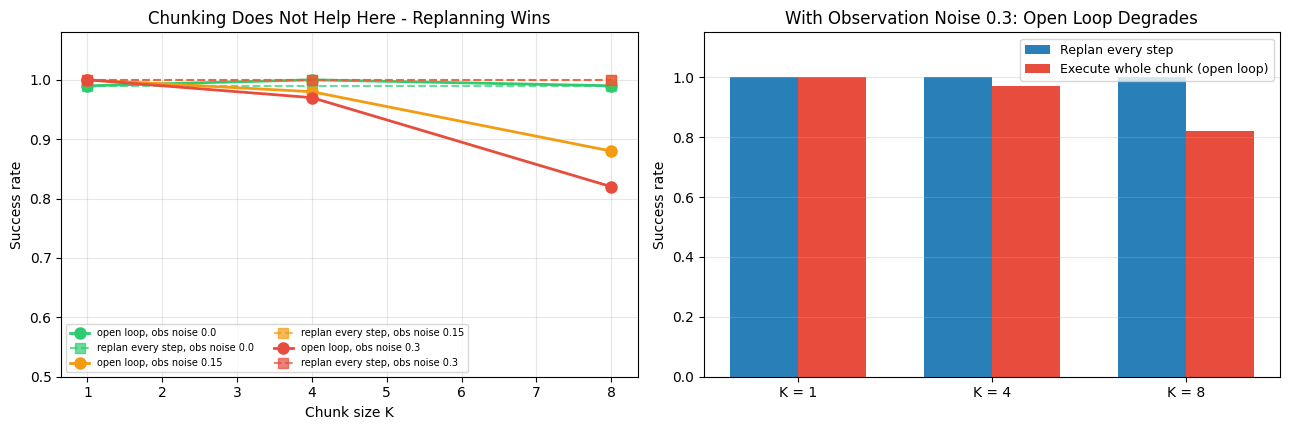

  K   noise   replan   open loop
  1    0.00     0.99        0.99
  1    0.15     1.00        1.00
  1    0.30     1.00        1.00
  4    0.00     0.99        1.00
  4    0.15     1.00        0.98
  4    0.30     1.00        0.97
  8    0.00     0.99        0.99
  8    0.15     1.00        0.88
  8    0.30     1.00        0.82


In [11]:
# ============================================================
# 図6: Action Chunking の実測（K と観測ノイズ）
# ============================================================

chunk_sizes = [1, 4, 8]
noise_levels = [0.0, 0.15, 0.30]
chunk_results = {}

t0 = time.time()
for K in chunk_sizes:
    S, A, _, _ = collect_demos(100, chunk=K)
    net, _ = train_bc(S, A)
    for noise in noise_levels:
        chunk_results[(K, noise, "replan")] = evaluate_policy(
            net, chunk=K, execute_whole_chunk=False, obs_noise=noise)
        chunk_results[(K, noise, "open")] = evaluate_policy(
            net, chunk=K, execute_whole_chunk=True, obs_noise=noise)
print(f"chunking experiment finished in {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
for noise, color in zip(noise_levels, ["#2ECC71", "#F39C12", "#E74C3C"]):
    ax.plot(chunk_sizes, [chunk_results[(K, noise, "open")] for K in chunk_sizes],
            "o-", color=color, lw=2, ms=8, label=f"open loop, obs noise {noise}")
    ax.plot(chunk_sizes, [chunk_results[(K, noise, "replan")] for K in chunk_sizes],
            "s--", color=color, lw=1.5, ms=7, alpha=0.7,
            label=f"replan every step, obs noise {noise}")
ax.set_xlabel("Chunk size K")
ax.set_ylabel("Success rate")
ax.set_ylim(0.5, 1.08)
ax.set_title("Chunking Does Not Help Here - Replanning Wins")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
x = np.arange(len(chunk_sizes))
w = 0.35
noise = 0.30
ax.bar(x - w / 2, [chunk_results[(K, noise, "replan")] for K in chunk_sizes], w,
       color="#2980B9", label="Replan every step")
ax.bar(x + w / 2, [chunk_results[(K, noise, "open")] for K in chunk_sizes], w,
       color="#E74C3C", label="Execute whole chunk (open loop)")
ax.set_xticks(x); ax.set_xticklabels([f"K = {K}" for K in chunk_sizes])
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.15)
ax.set_title(f"With Observation Noise {noise}: Open Loop Degrades")
ax.legend(fontsize=9)
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print(f"{'K':>3s} {'noise':>7s} {'replan':>8s} {'open loop':>11s}")
for K in chunk_sizes:
    for noise in noise_levels:
        print(f"{K:3d} {noise:7.2f} {chunk_results[(K, noise, 'replan')]:8.2f}"
              f" {chunk_results[(K, noise, 'open')]:11.2f}")

### 効かなかった理由を考える — これが一番大事な節

実測では、**チャンクをまとめて実行すると（特に観測ノイズ下で）劣化**しました。
毎ステップ再計画する方が強い。ACT の主張と逆です。

**手法が悪いのではなく、この環境がチャンクを必要としていない**からです。

| ACT がチャンクを必要とする条件 | ArmWorld はどうか |
|---|---|
| 人間のデモが**非マルコフ的**（迷い・癖・意図の引きずり） | `ScriptedExpert` は状態の関数（**完全にマルコフ的**） |
| 行動が**多峰性**を持つ（どちらに避けてもよい等） | 目標は1つ、最適な動きも1つ |
| **高頻度制御**（50Hz 以上）で1ステップが微小 | 1ステップで最大 0.12 動く（粗い） |
| 観測が高次元で**推論が遅い**（毎ステップ回せない） | 9次元の MLP（いくらでも回せる） |

つまり ArmWorld には「チャンクで解決すべき問題」が存在しません。
チャンクは**開ループ実行の分だけフィードバックを捨てる**ので、
得るものがなければ純粋な損になります。観測ノイズ下での劣化がまさにそれです。

> **教材としての含意**: 手法は「どの問題を解くために作られたか」とセットで覚える。
> ベンチマークで効いた手法が自分の設定で効くとは限りません。
> 次章（172 Diffusion Policy）では、**多峰性のあるデモ**を意図的に作ります。
> そこでは1ステップ回帰が原理的に失敗し、分布を出力する方針が必要になります。

---

<a id="summary"></a>
## 9. まとめとチートシート

### この章で学んだこと

- **BC は教師あり学習そのもの**。報酬も価値関数も探索も要らない。
  試行0回で、170 の A2C（2,000エピソード）と同等以上に届いた。
- **デモ数が性能を決める**。この環境では30本程度で実用域。訓練 MSE は指標にならない。
- **共変量シフトは実在する**。分布外の初期姿勢で BC(30) は大きく落ち、
  専門家は落ちなかった（＝環境のせいではない）。デモを増やすと回復する。
- **DAgger は訓練分布をテスト分布に寄せる**という発想。代償は専門家への常時問い合わせ。
- **一様ビン分割**で行動をトークンにできる（RT-2 型）。
  離散化の代償は**タスクの許容誤差との関係**で決まる。許容誤差が緩ければビン3個でも足りる。
- **VQ コードブック**はデータに出てくる動きの型だけを語彙にする。
  144 の VQ-VAE を行動空間へ直接適用した形。
- **Action Chunking はこの環境では効かなかった**。手法の前提（非マルコフ性・多峰性・
  高頻度制御）が成立していないため。**効く条件を理解して使う**。

### チートシート

```python
# Behavior Cloning（これだけ）
loss = ((policy(states) - expert_actions) ** 2).mean()

# ビン分割トークン化（RT-2 型）
centers = np.linspace(-1, 1, n_bins)
tokens  = np.abs(actions[:, :, None] - centers[None, None, :]).argmin(-1)
loss    = F.cross_entropy(logits.reshape(-1, n_bins), tokens.reshape(-1))
action  = centers[logits.argmax(-1)]            # デコード

# 行動チャンク（K ステップ分を1つの教師信号にする）
padded = np.concatenate([a, np.tile(a[-1:], (K, 1))])
chunks = np.stack([padded[i:i + K].reshape(-1) for i in range(len(states))])

# VQ コードブック（k-means は VQ の最も素朴な形）
codebook, labels, _ = learn_codebook(chunks, codebook_size)
loss = F.cross_entropy(net(states), labels)     # 「どの動きの型か」の分類
```

### よくある間違い

| 間違い | 何が起きるか | 対処 |
|---|---|---|
| 訓練 MSE で BC の良さを判断する | 少量データの方が訓練誤差は小さい | 必ず環境で成功率を測る |
| 分布内だけで評価する | 共変量シフトを見逃す | 初期状態を分布外にして測る |
| デモを増やせば必ず解決すると考える | カバーされない領域は残る | 見せたい状態を意図的に見せる（DAgger の発想） |
| ビン数を増やせば良くなると考える | 許容誤差次第で無意味／分類が難しくなり逆に悪化する | 許容誤差・量子化誤差・データ量の3つで決める |
| 論文で効いた手法を前提確認せず使う | Action Chunking のように逆効果になる | 手法が解く問題を自分の設定で確認する |
| 一様ビンで語彙を使い切ったつもりになる | 専門家の行動は端に偏り、中間ビンが余る | 分布を見る／VQ を使う |

### 次のノートブックへ

本章の BC は**1つの状態に1つの行動**を対応させる回帰でした。
では、**正解が複数ある**場合はどうなるでしょうか。

障害物を左から避けても右から避けてもよいとき、回帰は両者の**平均**を学びます。
平均は「障害物に正面衝突する」行動です。

これが Notebook 172（Diffusion Policy）の出発点です。
方針を「分布を出力するもの」として作り直します。
拡散モデル（Notebook 37-43）が、ここで方針として再登場します。

---

<a id="quiz"></a>
## 10. 自己評価クイズ

### Q1: BC と方針勾配の必要物の違い

**問題**: Behavior Cloning が必要とするものと、方針勾配（170）が必要とするものを比べ、
実機ロボットで BC が好まれる理由を述べてください。

<details>
<summary>答えを見る</summary>

BC は **(状態, 専門家の行動) の対**だけを必要とし、環境との試行も報酬関数も要りません。
方針勾配は環境との試行（本章の比較では2,000エピソード）と報酬の設計が必要です。

実機では ①失敗が物理的な損害になる ②試行に実時間がかかる ③報酬を自動計測する装置を
作るのが難しい（「掴めたか」をどう測る？）という事情があり、
「人間が数十回見せる」方が圧倒的に安く速いため BC が好まれます。
</details>

---

### Q2: 共変量シフトの機構

**問題**: BC の訓練とテストで何の分布が違うのかを明示し、
誤差が $O(\epsilon T)$ ではなく $O(\epsilon T^2)$ で増える理由を説明してください。

<details>
<summary>答えを見る</summary>

訓練データの状態分布は専門家の方針が訪れる $d^{\pi^*}$、テスト時は学習した方針が
訪れる $d^{\pi_\theta}$ です。教師あり学習の i.i.d. 前提が崩れています。

1ステップの誤り率 $\epsilon$ で方針が逸れると、次の状態は訓練分布から少し外れます。
外れた状態での誤り率はさらに高いので、もっと外れます。この**自己増幅**があるため、
各ステップの誤りが独立に足し算される $O(\epsilon T)$ ではなく、
「いつ逸れたか」×「その後の全ステップ」の二重和になり $O(\epsilon T^2)$ になります。
</details>

---

### Q3: 離散化の粒度

**問題**: 本章の実験で、許容誤差 0.15 ではビン3個でも成功率が落ちなかったのに、
許容誤差 0.05 では落ちました。この結果から「行動を何分割すべきか」について
何が言えますか。

<details>
<summary>答えを見る</summary>

**行動空間だけを見ても決められない**ということです。決めるのはタスクが要求する精度です。

量子化誤差（行動空間の性質）が、1エピソードを通じて蓄積したときに
タスクの許容誤差（タスクの性質）を超えるかどうかで決まります。
挿入や把持のような精密作業では細かいビンが必要で、
大まかなリーチングなら粗いビンで足ります。

実務的な手順は「許容誤差を先に決め、量子化誤差がその数分の1に収まるビン数を選ぶ」です。
</details>

---

### Q4: VQ と一様ビン分割

**問題**: 一様ビン分割と VQ コードブックの違いを、本章で観察した
「専門家の行動が端のビンに集中する」という事実と関連づけて説明してください。

<details>
<summary>答えを見る</summary>

一様ビン分割は**データを見ずに**行動空間を等分します。専門家が端の値ばかり使うなら、
中間のビンはほとんど使われず、語彙が無駄になります
（本章の図4右でこの偏りを確認しました）。

VQ はデータに合わせてコードを配置するので、よく使われる領域に細かく、
使われない領域には割り当てません。さらに本章では $K$ ステップの塊を1コードにしたので、
各コードが「動きの型（movement primitive）」になり、
時間的な構造まで語彙に取り込んでいます。

代償は、コードブックがデータ依存になること（新しい動きが語彙に無い）と、
一様ビンのように「デコードが自明」でなくなることです。
</details>

---

### Q5: 手法の前提を確認する

**問題**: 本章の Action Chunking は実測で逆効果でした。
ACT がチャンクを必要とした条件を3つ挙げ、ArmWorld でそれらが成立しない理由を述べてください。

<details>
<summary>答えを見る</summary>

1. **非マルコフ的なデモ**: 人間の操作は直前の意図を引きずる。
   ArmWorld の `ScriptedExpert` は状態の決定論的な関数なので完全にマルコフ的。
2. **多峰性**: 人間は同じ状況で違う動きをする。ArmWorld の目標は1つで最適動作も1つ。
3. **高頻度制御**: 50Hz 以上では1ステップが微小で、誤差の累積と震えが問題になる。
   ArmWorld は1ステップで最大 0.12 動く粗い制御。

チャンクの実行は**その区間のフィードバックを捨てる**ことなので、
得るものがなければ損だけが残ります。観測ノイズを入れると、
捨てたフィードバックの価値がそのまま成功率の差として現れました。
</details>

In [12]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 171 完了: 模倣学習と行動トークン化")
print("=" * 70)
print(f'''
【Behavior Cloning】

  デモ100本 / 試行0回 で 成功率 {bc_success:.2f}
  （170 の A2C は 2,000 エピソードの試行で 0.96）

  デモ数:  ''' + "  ".join(f"{d['n']}本={d['success']:.2f}" for d in data_curve) + f'''

【共変量シフト】

  BC(30本)  分布内 {rows[0][1]:.2f}  ->  分布外 {rows[0][2]:.2f}
  BC(300本) 分布内 {rows[1][1]:.2f}  ->  分布外 {rows[1][2]:.2f}
  専門家    分布外 {expert_ood:.2f}   <- 環境のせいではない

【行動の離散化】

  許容誤差 0.15: ''' + "  ".join(f"bins{r['bins']}={r['success']:.2f}" for r in results_bins[0.15]["rows"]) + f'''
  許容誤差 0.05: ''' + "  ".join(f"bins{r['bins']}={r['success']:.2f}" for r in results_bins[0.05]["rows"]) + f'''
  -> 離散化の代償はタスクの許容誤差で決まる

【VQ コードブック（K=4 のチャンク）】

  ''' + "  ".join(f"size{r['k']}={r['success']:.2f}" for r in vq_rows) + f'''

【Action Chunking】

  観測ノイズ 0.30: 毎ステップ再計画 {chunk_results[(8, 0.30, "replan")]:.2f}
                   開ループ実行(K=8) {chunk_results[(8, 0.30, "open")]:.2f}
  -> この環境は chunking を必要としていない（手法の前提が成立していない）

【次章への問い】

  正解が複数あるとき、回帰は「平均」を学んでしまう。
  障害物を左右どちらから避けてもよいなら、平均は正面衝突である。
  -> Notebook 172: Diffusion Policy
''')
print("=" * 70)

Notebook 171 完了: 模倣学習と行動トークン化

【Behavior Cloning】

  デモ100本 / 試行0回 で 成功率 0.99
  （170 の A2C は 2,000 エピソードの試行で 0.96）

  デモ数:  3本=0.38  10本=0.81  30本=0.94  100本=0.99  300本=0.99

【共変量シフト】

  BC(30本)  分布内 0.94  ->  分布外 0.09
  BC(300本) 分布内 0.99  ->  分布外 0.97
  専門家    分布外 0.99   <- 環境のせいではない

【行動の離散化】

  許容誤差 0.15: bins3=0.98  bins5=0.99  bins11=0.99  bins21=0.99
  許容誤差 0.05: bins3=0.81  bins5=0.96  bins11=0.94  bins21=0.88
  -> 離散化の代償はタスクの許容誤差で決まる

【VQ コードブック（K=4 のチャンク）】

  size8=0.92  size16=0.96  size32=0.97  size64=0.97

【Action Chunking】

  観測ノイズ 0.30: 毎ステップ再計画 1.00
                   開ループ実行(K=8) 0.82
  -> この環境は chunking を必要としていない（手法の前提が成立していない）

【次章への問い】

  正解が複数あるとき、回帰は「平均」を学んでしまう。
  障害物を左右どちらから避けてもよいなら、平均は正面衝突である。
  -> Notebook 172: Diffusion Policy

